In [1]:
Landuse_map = 'HILDA+_trimmed'

In [2]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy
import numpy as np
from tqdm import tqdm
import pandas as pd
#from numpy import *

"""
1. Load your evaporation dataset here
"""
print('To run the model, your data format should be:')
print('Latitude = [ 90 → -90 ]')
print('Longitude = [ 0 → 360 ]')
print(' ')

lats=np.arange(90,-90,-0.5)
lons=np.arange(0,360,0.5)

Evap_agg = xr.open_mfdataset('/home/chandra/data/Kruger/era5/evap_ERA5_monthly_averaged_reanalysis_resampled_monthly_mm_per_month_0.5degree.nc').e[:,::-1].sel(time = slice('2008','2017'))
# Convert to multi-year mean
Evap_agg = Evap_agg.groupby('time.month').mean(dim = 'time')
Evap_agg = (Evap_agg.where(Evap_agg > 0))

print('Your Evaporation data:')
print('Latitude = [', Evap_agg.lat[0].values, '→', Evap_agg.lat[-1].values, ']')
print('Longitude = [', Evap_agg.lon[0].values, '→', Evap_agg.lon[-1].values, ']')


"""
2. Funtion for forwardtracking (monthly) [Annual can be derived using 'np.sum' funtion] 
"""
### Forward tracking
def get_closest_index(lats,lat):
    import operator
    lat_index, min_value = min(enumerate(abs(lats-lat)), key=operator.itemgetter(1))
    return lat_index

    
def MR_footprint_forward(month, latitude, longitude):
    latidx=get_closest_index(lats,latitude)
    lonidx=get_closest_index(lons,longitude)
    
    MR = xr.open_dataset('/home/chandra/data/Paper4_Self-influencing_feedback/utrack_climatology/utrack_climatology_0.5_'+
                                                         str(month).zfill(2)+'.nc').moisture_flow
    fp = MR[get_closest_index(lats,latitude), get_closest_index(lons,longitude),:,:].values
    fp=fp*-0.1
    fp=np.e**fp
    fp[fp==1]=0
    forward_fp=fp/np.nansum(fp)
    #print(np.nansum(forward_fp).round(2))
    forward_fp = forward_fp*((Evap_agg[month-1])[get_closest_index(lats,latitude), 
                                                 get_closest_index(lons,longitude)].values)
    return forward_fp


def absolute_forward_tracking(j):
    Evap_footprint_monthly = np.zeros(shape=(12,360,720))
    Evap_footprint_monthly_final  = np.zeros(shape=(12,360,720))
    #for j in tqdm(range(Screened_data.shape[0])):
    latitude, longitude = np.array(Screened_data.loc[j])
    #print(latitude, longitude, '\n')
    for i in tqdm(range(12)):
        Evap_footprint_monthly[i,:,:] = MR_footprint_forward(i+1,latitude,longitude)
    Evap_footprint_monthly_final = Evap_footprint_monthly_final + Evap_footprint_monthly

    #Evap_footprint_monthly_sum = xr.DataArray(Evap_footprint_monthly_final, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
    #             dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
    return Evap_footprint_monthly_final

To run the model, your data format should be:
Latitude = [ 90 → -90 ]
Longitude = [ 0 → 360 ]
 
Your Evaporation data:
Latitude = [ 89.75 → -89.75 ]
Longitude = [ 0.0 → 359.5 ]


In [3]:
"""
3. Defining the data for forward tracking
"""
data = xr.open_dataset('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc').Dominance

data['x'] = data.x.values%360
data

<xarray.DataArray 'Dominance' (y: 144, x: 162)>
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]])
Coordinates:
  * y        (y) float64 15.75 15.25 14.75 14.25 ... -54.25 -54.75 -55.25 -55.75
  * x        (x) float64 250.8 251.2 251.8 252.2 ... 329.8 330.2 330.8 331.2
Attributes:
    name:          Dominance
    long_name:     Dominance
    grid_mapping:  spatial_ref

In [4]:
Lat = []
for lat in np.argwhere(data.values == 1).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 1).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Smallholders_'+Landuse_map+'.nc')


100%|██████████| 12/12 [01:07<00:00,  5.05s/it]


100%|██████████| 12/12 [01:07<00:00,  5.61s/it]

100%|██████████| 12/12 [01:09<00:00,  5.75s/it]

100%|██████████| 12/12 [01:11<00:00,  5.98s/it]

100%|██████████| 12/12 [01:11<00:00,  5.98s/it]

100%|██████████| 12/12 [01:12<00:00,  6.07s/it]

  0%|          | 0/12 [00:00<?, ?it/s]6.08s/it]

100%|██████████| 12/12 [00:48<00:00,  4.05s/it]

100%|██████████| 12/12 [01:05<00:00,  5.46s/it]

  8%|▊         | 1/12 [00:09<01:44,  9.52s/it]

 42%|████▏     | 5/12 [00:22<00:31,  4.45s/it]  File "/usr/lib/python3.8/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)


  File "/usr/lib/python3.8/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)







Process ForkPoolWorker-29:

Process ForkPoolWorker-32:




Process ForkPoolWorker-33:


Process ForkPoolWorker-48:
Process ForkPoolWorker-41:
Process ForkPoolWorker-44:
Process ForkPoolWorker-34:
Process ForkPoolWorke

In [ ]:
Lat = []
for lat in np.argwhere(data.values == 2).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 2).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})


#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Mediumholders_'+Landuse_map+'.nc')


In [ ]:
Lat = []
for lat in np.argwhere(data.values == 3).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 3).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})


#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Largeholders_'+Landuse_map+'.nc')


  0%|          | 0/12 [00:00<?, ?it/s]HDF5-DIAG: Error detected in HDF5 (1.12.2) HDF5-DIAG: Error detected in HDF5 (1.12.2) HDF5-DIAG: Error detected in HDF5 (1.12.2) thread 1thread 1thread 1:
:
:
  #000: H5A.c line 528 in H5Aopen_by_name(): can't open attribute
  #000: H5A.c line 528 in H5Aopen_by_name(): can't open attribute
  #000: H5A.c line 528 in H5Aopen_by_name(): can't open attribute
    major: Attribute
    major: Attribute
    major: Attribute
    minor: Can't open object
    minor: Can't open object
    minor: Can't open object
  #001: H5VLcallback.c line 1091 in H5VL_attr_open(): attribute open failed
  #001: H5VLcallback.c line 1091 in H5VL_attr_open(): attribute open failed
    major: Virtual Object Layer
    major: Virtual Object Layer
  #001: H5VLcallback.c line 1091 in H5VL_attr_open(): attribute open failed
    minor: Can't open object
    minor: Can't open object
    major: Virtual Object Layer
    minor: Can't open object
  #002: H5VLcallback.c line 1058 in H5VL__at

Text(0.5, 1.0, 'Forwardtracking: mm/year')

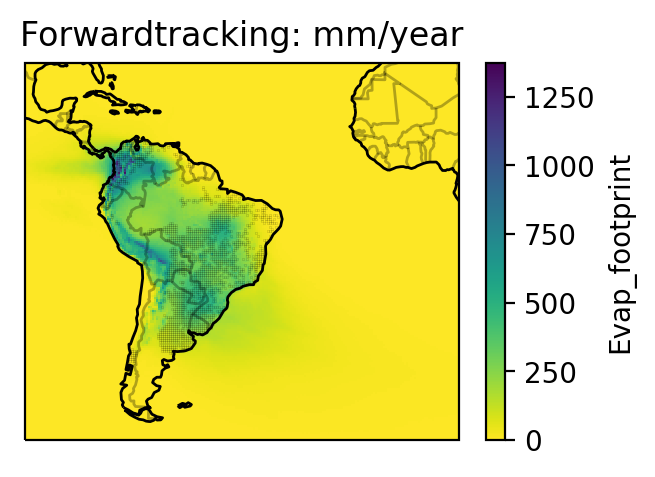

In [25]:
fig = plt.figure(figsize=(3.5, 2.5), dpi = 200)
ax = [plt.subplot(111,projection=ccrs.PlateCarree(), aspect='auto')]
Evap_footprint_monthly_sum.sum(dim = 'month').plot(ax = ax[0], vmin = 0, cmap = 'viridis_r',)
ax[0].coastlines(lw = 1)
ax[0].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=.3)
ax[0].set_xlim(-100,10)
ax[0].set_ylim(-60, 30)
ax[0].scatter(np.array(Screened_data['Lon']), np.array(Screened_data['Lat']), c='black', alpha = 0.7, s = 0.01, marker = '.')
ax[0].set_title('Forwardtracking: mm/year')

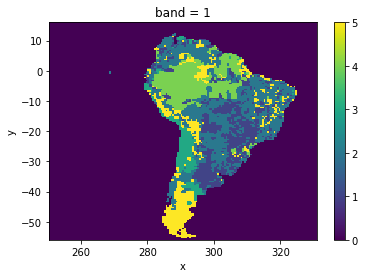

In [6]:
Lat = []
for lat in np.argwhere(data[0].values > 0).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values > 0).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})


#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Actor_dominance_HilDA+/Forwardtracking_Largeholders.nc')

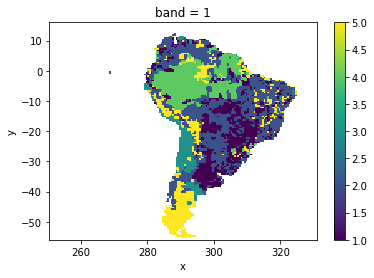

In [13]:
data.where((data.values >= 1) & (data.values <= 5)).plot()